# IMPORTS

In [1]:

import os
import random
import time
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from copy import deepcopy

from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.base import BaseEstimator, RegressorMixin

import torch
import torch.nn as nn
import torch.optim as optim

# CONSISTENT SEED FOR REPRODUCABILITY

In [2]:
def set_seed(seed=4):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

Device: cuda


# UTLITY - OPTIMIZER METRICS

In [3]:
def smape(y_true, y_pred):
    # works on arrays in original scale
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    return np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8))


# DATA IMPORT / PREPROCESSING / SPLITS

In [4]:
df = pd.read_csv('/kaggle/input/finale/FINAL.csv')
df = df[:-2]  # omit unnecessary rows

# convert strings with commas to numbers
df = df.apply(lambda col: col.map(lambda x: pd.to_numeric(x.replace(',', ''), errors='coerce')
                                 if isinstance(x, str) and ',' in x else x))


def fit_and_transform_onehot(df_train, cat_cols=['Region', 'Census 2021 Municipality Class', 'Province']):
    """
    Fit OneHotEncoder on df_train[cat_cols] and return:
      - encoder (fitted)
      - df_encoded (train with onehot columns)
      - onehot_feature_names (list)
    """
    enc = OneHotEncoder(sparse=False, handle_unknown='ignore')
    enc_arr = enc.fit_transform(df_train[cat_cols])
    enc_cols = enc.get_feature_names_out(cat_cols).tolist()
    enc_df = pd.DataFrame(enc_arr, columns=enc_cols, index=df_train.index)
    df_out = pd.concat([df_train.drop(columns=cat_cols), enc_df], axis=1)
    return enc, df_out, enc_cols


def transform_onehot(df_new, encoder, cat_cols=['Region', 'Census 2021 Municipality Class', 'Province']):
    enc_arr = encoder.transform(df_new[cat_cols].fillna("missing"))
    enc_cols = encoder.get_feature_names_out(cat_cols).tolist()
    enc_df = pd.DataFrame(enc_arr, columns=enc_cols, index=df_new.index)
    df_out = pd.concat([df_new.drop(columns=cat_cols, errors='ignore'), enc_df], axis=1)
    return df_out


# Feature list base 
base_numeric_features = [
    'Population Density(person per km2)',
    'Total Population 2011',
    'HDI Geometric Mean',
    'Annual Mean Temp',
    'Agriculture % of economically active population in agriculture (2021)'
]


df['Population Density(person per km2)'] = pd.to_numeric(df['Population Density(person per km2)'], errors='coerce')
df['Population Density(person per km2)'] = np.log1p(df['Population Density(person per km2)'])
df['Total Population 2011'] = np.log1p(pd.to_numeric(df['Total Population 2011'], errors='coerce'))

raw_X = df.copy()
y_raw = raw_X["Total MSW Generation (tons/day)"].copy()
y_log = np.log1p(y_raw)

# Create stratified indices 
y_bins = pd.qcut(y_log, q=10, labels=False, duplicates='drop')
sss1 = StratifiedShuffleSplit(n_splits=1, train_size=0.6, random_state=4)
train_idx, temp_idx = next(sss1.split(raw_X, y_bins))

sss2 = StratifiedShuffleSplit(n_splits=1, train_size=0.5, random_state=4)
val_idx_rel, test_idx_rel = next(sss2.split(raw_X.iloc[temp_idx], y_bins.iloc[temp_idx]))
val_idx, test_idx = temp_idx[val_idx_rel], temp_idx[test_idx_rel]

df_train = raw_X.iloc[train_idx].copy()
df_val   = raw_X.iloc[val_idx].copy()
df_test  = raw_X.iloc[test_idx].copy()

y_train_raw = y_raw.iloc[train_idx].copy()
y_val_raw   = y_raw.iloc[val_idx].copy()
y_test_raw  = y_raw.iloc[test_idx].copy()

y_train_log = y_log.iloc[train_idx].copy()
y_val_log   = y_log.iloc[val_idx].copy()
y_test_log  = y_log.iloc[test_idx].copy()

print("Sizes — train, val, test:", len(df_train), len(df_val), len(df_test))

cat_cols = ['Region', 'Census 2021 Municipality Class', 'Province']
encoder, df_train_enc, enc_cols = fit_and_transform_onehot(df_train, cat_cols=cat_cols)
df_val_enc = transform_onehot(df_val, encoder, cat_cols=cat_cols)
df_test_enc = transform_onehot(df_test, encoder, cat_cols=cat_cols)

drop_cols = ['Region_Hill', 'Census 2021 Municipality Class_SME', 'Province_Karnali']
for c in drop_cols:
    if c in df_train_enc.columns:
        df_train_enc = df_train_enc.drop(columns=c)
    if c in df_val_enc.columns:
        df_val_enc = df_val_enc.drop(columns=c)
    if c in df_test_enc.columns:
        df_test_enc = df_test_enc.drop(columns=c)

for d in (df_train_enc, df_val_enc, df_test_enc):
    if 'Population Density(person per km2)' in d.columns:
        d['Population Density(person per km2)'] = pd.to_numeric(d['Population Density(person per km2)'], errors='coerce')
    if 'Total Population 2011' in d.columns:
        d['Total Population 2011'] = pd.to_numeric(d['Total Population 2011'], errors='coerce')

feature_cols = base_numeric_features + \
               [c for c in df_train_enc.columns if c.startswith('Census 2021 Municipality Class_') or c.startswith('Region_') or c.startswith('Province')]

def ensure_cols(df_in, cols):
    df_copy = df_in.copy()
    for col in cols:
        if col not in df_copy.columns:
            df_copy[col] = 0.0
    return df_copy[cols]

X_train = ensure_cols(df_train_enc, feature_cols)
X_val   = ensure_cols(df_val_enc, feature_cols)
X_test  = ensure_cols(df_test_enc, feature_cols)

scaler = RobustScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

selector = SelectKBest(score_func=f_regression, k='all').fit(X_train_scaled, y_train_log)
X_train_sel = selector.transform(X_train_scaled)
X_val_sel   = selector.transform(X_val_scaled)
X_test_sel  = selector.transform(X_test_scaled)

print("Feature dims after selection:", X_train_sel.shape)

Sizes — train, val, test: 69 23 24
Feature dims after selection: (69, 15)


/usr/local/lib/python3.11/dist-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


# Neural Network Architecture

In [5]:
class NeuralNetwork(nn.Module):
    def __init__(self, input_size, hidden_sizes, dropout):
        super().__init__()
        layers = []
        in_size = input_size
        for h in hidden_sizes:
            layers.append(nn.Linear(in_size, h))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            in_size = h
        layers.append(nn.Linear(in_size, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

class TorchNN(BaseEstimator, RegressorMixin):
    def __init__(self, input_size, hidden_sizes, lr=0.001, epochs=800, weight_decay=1e-5, dropout=0.1, device=device):
        self.input_size = input_size
        self.hidden_sizes = hidden_sizes
        self.lr = lr
        self.epochs = int(epochs)
        self.weight_decay = weight_decay
        self.dropout = dropout
        self.device = device
        self.model = NeuralNetwork(input_size, hidden_sizes, dropout).to(self.device)
        
    def fit(self, X, y, X_val=None, y_val=None):
        set_seed(4)
        X_tensor = torch.tensor(X, dtype=torch.float32).to(self.device)
        y_tensor = torch.tensor(y.values if hasattr(y, "values") else y, dtype=torch.float32).view(-1,1).to(self.device)

        if X_val is not None and y_val is not None:
            X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(self.device)
            y_val_tensor = torch.tensor(y_val.values if hasattr(y_val, "values") else y_val, dtype=torch.float32).view(-1,1).to(self.device)
        else:
            X_val_tensor = y_val_tensor = None

        criterion = nn.HuberLoss()
        optimizer = optim.Adam(self.model.parameters(), lr=self.lr, weight_decay=self.weight_decay)

        best_loss = float('inf'); best_state = None
        patience, wait = 50, 0

        for epoch in range(self.epochs):
            self.model.train()
            optimizer.zero_grad()
            preds = self.model(X_tensor)
            loss = criterion(preds, y_tensor)
            loss.backward()
            optimizer.step()
            if X_val_tensor is not None:
                self.model.eval()
                with torch.no_grad():
                    vloss = criterion(self.model(X_val_tensor), y_val_tensor).item()
                if vloss < best_loss - 1e-8:
                    best_loss = vloss
                    best_state = deepcopy(self.model.state_dict())
                    wait = 0
                else:
                    wait += 1
                    if wait >= patience:
                        break

        if best_state is not None:
            self.model.load_state_dict(best_state)
        return self

    def predict(self, X):
        self.model.eval()
        X_tensor = torch.tensor(X, dtype=torch.float32).to(self.device)
        with torch.no_grad():
            preds = self.model(X_tensor).cpu().numpy().flatten()
        return preds

# Optimial Hyperparameter Space Found from Large Iterations

In [6]:
best_trial_params = {'num_layers' : 10,
    'n_units_l0': 854, 'n_units_l1': 499, 'n_units_l2': 149, 'n_units_l3': 196, 'n_units_l4': 835, 'n_units_l5': 571, 'n_units_l6': 583, 'n_units_l7': 385, 'n_units_l8': 992, 'n_units_l9': 157, 'lr': 0.005156551798785213, 
     'dropout': 0.078, 'weight_decay': 5.5840126291030944e-05, 'epochs': 962}
# build hidden sizes list
num_layers = int(best_trial_params['num_layers'])
hidden_sizes = [int(best_trial_params[f'n_units_l{i}']) for i in range(num_layers)]
print("Hidden sizes:", hidden_sizes)

Hidden sizes: [854, 499, 149, 196, 835, 571, 583, 385, 992, 157]


# Training Final Model 

In [7]:
final_model = TorchNN(
    input_size=X_train_sel.shape[1],
    hidden_sizes=hidden_sizes,
    lr=best_trial_params['lr'],
    epochs=best_trial_params['epochs'],
    weight_decay=best_trial_params['weight_decay'],
    dropout=best_trial_params['dropout'],
    device=device
)

print("Training final model...")
start = time.time()
final_model.fit(X_train_sel, y_train_log, X_val_sel, y_val_log)
print(f"Training done in {time.time()-start:.1f} sec")


Training final model...
Training done in 4.0 sec


# Evaulation Metrices

In [8]:
def evaluate_model(model, X_sel, y_log, y_raw):
    preds_log = model.predict(X_sel)
    preds_raw = np.expm1(preds_log)  # convert back to original scale
    return {
        'R2': r2_score(y_raw, preds_raw),
        'MAE': mean_absolute_error(y_raw, preds_raw),
        'RMSE': mean_squared_error(y_raw, preds_raw, squared=False),
        'SMAPE': smape(y_raw, preds_raw),
        'y_true': y_raw.values,
        'y_pred': preds_raw
    }

results = {
    'Train': evaluate_model(final_model, X_train_sel, y_train_log, y_train_raw),
    'Val':   evaluate_model(final_model, X_val_sel,   y_val_log,   y_val_raw),
    'Test':  evaluate_model(final_model, X_test_sel,  y_test_log,  y_test_raw)
}

print("\n📊 Final Evaluation Metrics:")
print(pd.DataFrame({k: {m: v for m,v in results[k].items() if m not in ['y_true','y_pred']} for k in results}).T)



📊 Final Evaluation Metrics:
             R2       MAE      RMSE     SMAPE
Train  0.991557  2.742166  5.206640  0.225820
Val    0.934996  2.170391  3.142443  0.223532
Test   0.970139  2.203838  2.910588  0.258270


# PLOT

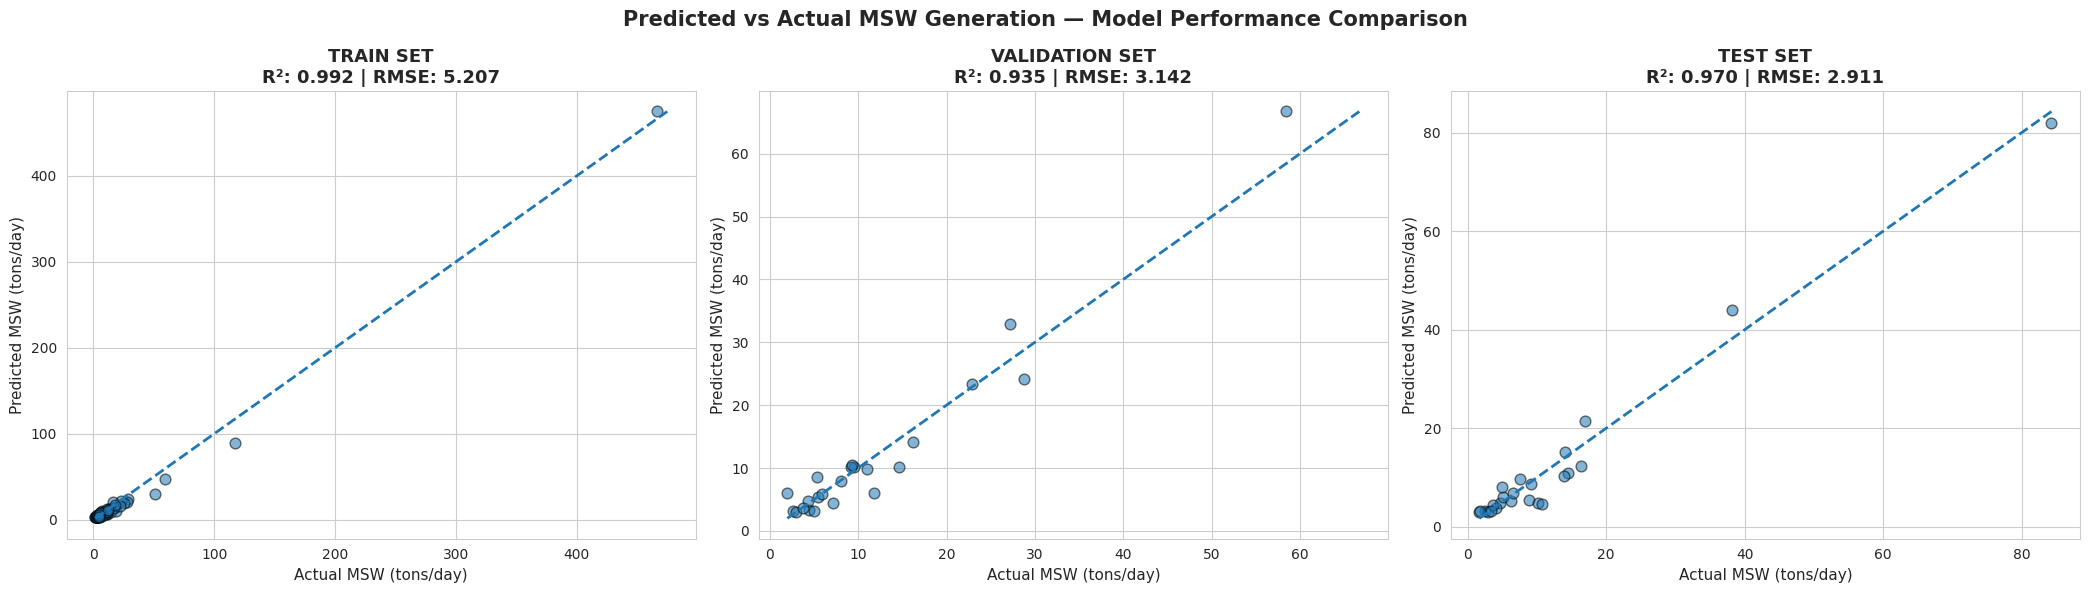

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

def plot_pair(ax, y_true, y_pred, title: str):
    """Utility to create a clean scatter with metrics shown."""
    r2  = r2_score(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred, squared=False)

    ax.scatter(y_true, y_pred, alpha=0.55, edgecolor='black', s=60)
    
    # 1:1 line
    mn = min(min(y_true), min(y_pred))
    mx = max(max(y_true), max(y_pred))
    ax.plot([mn, mx], [mn, mx], linestyle="--", linewidth=2)

    ax.set_title(f"{title}\nR²: {r2:.3f} | RMSE: {rmse:.3f}", fontsize=13, weight='bold')
    ax.set_xlabel("Actual MSW (tons/day)", fontsize=11)
    ax.set_ylabel("Predicted MSW (tons/day)", fontsize=11)

    ax.tick_params(axis='both', labelsize=10)

# Plot Layout
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

plot_pair(axes[0], results['Train']['y_true'], results['Train']['y_pred'], "TRAIN SET")
plot_pair(axes[1], results['Val']['y_true'],   results['Val']['y_pred'],   "VALIDATION SET")
plot_pair(axes[2], results['Test']['y_true'],  results['Test']['y_pred'],  "TEST SET")

plt.suptitle("Predicted vs Actual MSW Generation — Model Performance Comparison",
             fontsize=15, weight='bold')
plt.tight_layout()
plt.show()


# MASS PREDICTOR

In [ ]:
def prepare_features_timeseries_filtered(df_new, year, encoder, feature_cols):
    dfp = df_new.copy()

    dfp.columns = (
        dfp.columns.astype(str)
        .str.replace('\u00A0', ' ', regex=False)   # remove non-breaking space
        .str.replace('\u200B', '', regex=False)    # remove zero-width space
        .str.replace('\n', ' ', regex=False)       # remove line breaks (MAIN FIX)
        .str.replace('\r', ' ', regex=False)
        .str.replace(r'\s+', ' ', regex=True)      # collapse multiple spaces
        .str.strip()
    )
    
    # Filter municipalities that do NOT contain "Gaunpalika"
    dfp = dfp[~dfp['Municipality'].str.contains("Gaunpalika", case=False, na=False)].copy()
    
    # categorical columns
    cat_cols = ['Region', 'Census 2021 Municipality Class', 'Province']
    drop_cols = ['Region_Hill', 'Census 2021 Municipality Class_SME', 'Province_Karnali']
    
    # yearly columns
    pop_col = str(year)
    temp_col = f'temp_{year}'
    dens_col = f'density_{year}'
    hdi_col = f'HDI HDR format {year}'  # HDI column for the specific year HDI HDR format 2022
    
    # assign yearly features
    dfp['Total Population 2011'] = np.log1p(pd.to_numeric(dfp[pop_col], errors='coerce'))
    dfp['Annual Mean Temp'] = pd.to_numeric(dfp[temp_col], errors='coerce')
    dfp['Population Density(person per km2)'] = np.log1p(pd.to_numeric(dfp[dens_col], errors='coerce'))
    
    # HDI as time-series feature
    dfp['HDI Geometric Mean'] = pd.to_numeric(dfp[hdi_col], errors='coerce')
    
    # constant features (if any remain constant across years)
    dfp['Agriculture % of economically active population in agriculture (2021)'] = pd.to_numeric(
        dfp['Agriculture % of economically active population in agriculture (2021)'], errors='coerce')
    
    # One-hot encode categorical columns
    dfp_enc = transform_onehot(dfp, encoder, cat_cols)
    
    # Drop unwanted columns
    for c in drop_cols:
        if c in dfp_enc.columns:
            dfp_enc = dfp_enc.drop(columns=c)
    
    # Ensure feature_cols exist
    for col in feature_cols:
        if col not in dfp_enc.columns:
            dfp_enc[col] = 0.0
    
    # select final features
    X_new = dfp_enc[feature_cols]
    X_new_scaled = scaler.transform(X_new)
    X_new_sel = selector.transform(X_new_scaled)
    
    return X_new_sel, dfp

# Main prediction function
def predict_timeseries_excel_filtered(filepath, model, encoder, feature_cols):
    df_new = pd.read_excel(filepath, sheet_name='Essential Data')
    df_new.columns = df_new.columns.astype(str).str.strip()  # fix KeyError
    
    years = list(range(2021, 2052))  # 2021-2051
    all_preds = []
    df_filtered = None
    
    for i, year in enumerate(years):
        X_new_sel, df_filtered = prepare_features_timeseries_filtered(df_new, year, encoder, feature_cols)
        preds_log = model.predict(X_new_sel)
        preds_raw = np.expm1(preds_log)
        all_preds.append(preds_raw)
    
    # Convert to DataFrame: columns = years, rows = municipalities
    preds_array = np.array(all_preds).T  # transpose to have shape (n_rows, n_years)
    preds_df = pd.DataFrame(preds_array, columns=[f'{y}' for y in years])
    
    # Include Municipality info from filtered df
    if df_filtered is not None and 'District' in df_filtered.columns and 'Municipality' in df_filtered.columns:
        preds_df.insert(0, 'District', df_filtered['District'].values)
        preds_df.insert(1, 'Municipality', df_filtered['Municipality'].values)
    
    return preds_df

# Example usage
excel_path = "/kaggle/input/final-hdi/HDI_HDR_Data (2).xlsx"
if os.path.exists(excel_path):
    results_df_filtered = predict_timeseries_excel_filtered(excel_path, final_model, encoder, feature_cols)
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    output_path = f"/kaggle/working/prediction_results_filtered_{ts}.xlsx"
    results_df_filtered.to_excel(output_path, index=False)
    print(f"✅ Filtered predictions saved to: {output_path}")
    print(results_df_filtered.head())
else:
    print(f"Excel file not found at {excel_path}. Skipping predict step.")

✅ Filtered predictions saved to: /kaggle/working/prediction_results_filtered_20260526_163056.xlsx
        District               Municipality      2021      2022      2023  \
0      Taplejung     Phungling Municipality  4.918165  4.943918  4.974545   
1  Sankhuwasabha    Khandabari Municipality  5.176768  5.246643  5.316271   
2  Sankhuwasabha  Panchakhapan Municipality  3.632265  3.640025  3.649930   
3  Sankhuwasabha     Chainapur Municipality  4.474218  4.544468  4.603764   
4  Sankhuwasabha          Madi Municipality  3.509208  3.553773  3.598085   

       2024      2025      2026      2027      2028  ...      2042      2043  \
0  5.002436  5.031168  5.056348  5.097653  5.125384  ...  5.712043  5.753496   
1  5.390468  5.468733  5.562419  5.637829  5.732909  ...  7.110273  7.224315   
2  3.675492  3.707735  3.744571  3.769493  3.842931  ...  4.930537  5.000967   
3  4.674752  4.735653  4.802116  4.851883  4.929222  ...  5.951745  6.045576   
4  3.614255  3.610975  3.613143  3.6099